# Project 7: NG Sampling vs ICT
Notebook membaca CSV hasil (`results/`), tidak menghitung ulang. Urutan mengikuti 14 pertanyaan pada Design Project.

**Data adalah SIMULASI** (data kerja asli tidak tersedia). Waktu ICT 3 menit per unit dan volume 4.000 unit per bulan adalah asumsi.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
R1, R2 = "../1-data-preparation/", "../2-analysis/"
rd = lambda p: pd.read_csv(p)

## Q1. OK rate harian ICT dan FCT, tren, dan hubungan antar hari

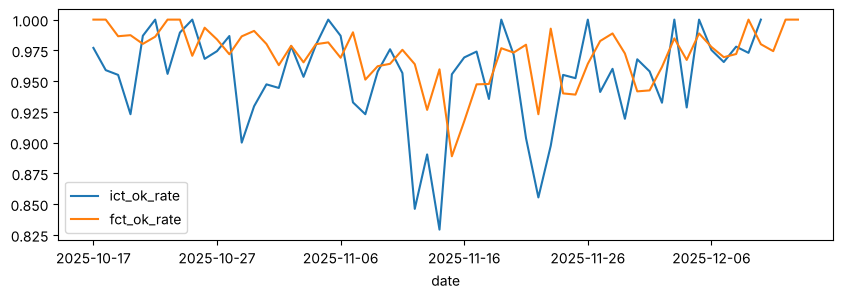

 minggu  hari  unit  ict_ok_rate  fct_ok_rate  skip_rate
      1     6   954        0.964        0.991      0.505
      2     6   889        0.979        0.987      0.470
      3     6   934        0.955        0.976      0.461
      4     6   952        0.955        0.969      0.483
      5     6   926        0.926        0.931      0.460
      6     6   954        0.923        0.958      0.471
      7     6   887        0.946        0.965      0.514
      8     6   900        0.970        0.979      0.477
 lag_hari  n_hari  korelasi  p_value
        0      47     0.248    0.092
        1      47     0.462    0.001
        2      46     0.462    0.001
        3      45     0.312    0.037
        4      44     0.159    0.302


In [2]:
d = rd(R2+"daily_summary.csv"); d = d[d.fct_tested > 0]
d.plot(x="date", y=["ict_ok_rate", "fct_ok_rate"], figsize=(10, 3)); plt.show()
print(rd(R2+"weekly_trend.csv").round(3).to_string(index=False)); print(rd(R2+"daily_lag_corr.csv").round(3).to_string(index=False))

## Q2. NG rate FCT: unit lolos ICT vs unit di-skip (uji Fisher)

In [3]:
print(rd(R2+'path_test.csv').round(4).T.to_string(header=False))

jalur             ICT    Skip
n                3815    3493
ng                 75     145
ng_rate        0.0197  0.0415
ci_low         0.0157  0.0354
ci_high        0.0246  0.0486
odds_ratio     2.1597  2.1597
relative_risk  2.1116  2.1116
p_fisher          0.0     0.0


## Q3. Mode NG per jalur

In [4]:
print(rd(R2+'mode_test.csv').round(3).to_string(index=False)); print(rd(R2+'mode_measurements.csv').round(1).to_string(index=False))

jalur  ng  vd  lc  porsi_vd  p_fisher  odds_ratio
  ICT  75  36  39     0.480     0.118       1.579
 Skip 145  86  59     0.593     0.118       1.579
fail_mode  vdrop_max_mv  leak_max_ua
       LC          37.1         17.3
       VD          88.6          4.1


## Q4. Kondisi dengan NG rate rendah saat di-skip

In [5]:
c = rd(R2+'conditions.csv'); print(c[['kondisi','nilai','n_skip','ng_skip','ng_rate_skip','ci_low','ci_high','cukup_unit','p_bonferroni','n_ict','ng_rate_ict']].round(3).to_string(index=False))

 kondisi   nilai  n_skip  ng_skip  ng_rate_skip  ci_low  ci_high  cukup_unit  p_bonferroni  n_ict  ng_rate_ict
  ic_lot   Lot_A     403        5         0.012   0.005    0.029        True         0.022    395        0.008
  ic_lot   Lot_B     422       52         0.123   0.095    0.158        True         0.000    480        0.054
  ic_lot   Lot_E     610       22         0.036   0.024    0.054        True         1.000    643        0.022
  ic_lot   Lot_H     444       19         0.043   0.028    0.066        True         1.000    434        0.012
  ic_lot   Lot_J     692       12         0.017   0.010    0.030        True         0.005    765        0.013
  ic_lot   Lot_K      13        3         0.231   0.082    0.503       False         0.428     12        0.083
  ic_lot   Lot_N     560       17         0.030   0.019    0.048        True         1.000    675        0.018
  ic_lot   Lot_R     349       15         0.043   0.026    0.070        True         1.000    411        0.010
 

## Q5. Jumlah unit minimum agar kesimpulan bisa dipercaya

In [6]:
print(rd(R2+'n_needed.csv').to_string(index=False)); print(rd(R2+'min_units_sensitivity.csv')[['min_unit','unit_aman','late_ng_rate_skip_aman','jam_ict_dihemat_per_bulan','net_late_ng_per_bulan']].round(3).to_string(index=False))

 ng_rate  margin  unit_dibutuhkan
    0.02    0.02              189
    0.02    0.01              753
    0.03    0.02              280
    0.03    0.01             1118
    0.04    0.02              369
    0.04    0.01             1476
    0.05    0.02              457
    0.05    0.01             1825
 min_unit  unit_aman  late_ng_rate_skip_aman  jam_ict_dihemat_per_bulan  net_late_ng_per_bulan
       10       1062                   0.030                     17.910                  7.980
       30       1062                   0.030                     17.910                  7.980
       60       1062                   0.030                     17.910                  7.980
      100        322                   0.032                      5.247                  0.473


## Q6. Unit NG di ICT: hasilnya di FCT

In [7]:
print(rd(R2+'ict_to_fct.csv').round(3).to_string(index=False))

ict_result  NG   OK    n  porsi_fct_ng
        NG  15  166  181         0.083
        OK  60 3574 3634         0.017


## Q7. Penelusuran sampel unit NG FCT

In [8]:
print(rd(R2+'ng_trace.csv').round(3).to_string(index=False))

                                                    ukuran  unit  porsi
                                               unit NG FCT   220  1.000
                             tidak pernah di-ICT (di-skip)   145  0.659
                                             pernah di-ICT    75  0.341
        pernah di-ICT dan OK di ICT (lolos ICT, NG di FCT)    60  0.273
pernah di-ICT dan NG di ICT (NG di FCT setelah diperbaiki)    15  0.068


## Q8. Sampel NG saja vs seluruh produksi

In [9]:
print(rd(R2+'ng_sample_vs_all.csv').round(3).to_string(index=False)); print(rd(R2+'ng_sample_draws.csv').round(3).T.to_string(header=False))

 kondisi  nilai_beda    chi2  p_value  selisih_porsi_maks
  ic_lot           8 137.711    0.000               0.231
 pcb_lot           6  55.399    0.000               0.142
conn_lot           4  17.951    0.000               0.106
  smt_op           6  12.030    0.034               0.061
smt_line           2   6.530    0.011               0.087
   shift           3   5.655    0.059               0.065
ukuran_sampel                              60
undian                                   2000
lot_ic_ng_rate_tertinggi                Lot_B
porsi_undian_lot_terbanyak_benar        0.991
lot_ic_volume_terbesar                  Lot_J
porsi_undian_lot_terbanyak_sama_volume    0.0


## Q9-Q11. Skenario aturan skip (estimated, walk-forward)

In [10]:
s = rd(R2+'skip_scenarios.csv'); print(s[['aturan','batas_late_ng','porsi_unit_aman','late_ng_rate_skip_aman','ng_rate_ict_aman','jam_ict_dihemat_per_bulan','tambahan_late_ng_per_bulan','unit_dialihkan_per_bulan','late_ng_dihindari_per_bulan','net_late_ng_per_bulan']].round(3).to_string(index=False))

            aturan  batas_late_ng  porsi_unit_aman  late_ng_rate_skip_aman  ng_rate_ict_aman  jam_ict_dihemat_per_bulan  tambahan_late_ng_per_bulan  unit_dialihkan_per_bulan  late_ng_dihindari_per_bulan  net_late_ng_per_bulan
       IC lot saja           0.02            0.280                   0.026             0.015                     29.379                       6.464                   587.588                       17.537                 11.073
       IC lot saja           0.03            0.473                   0.035             0.016                     49.961                      19.448                   999.214                       28.957                  9.509
       IC lot saja           0.04            0.634                   0.034             0.017                     66.206                      23.309                   684.368                       25.455                  2.146
       IC lot saja           0.05            0.760                   0.034             0.015    

## Q12. Checklist anonimisasi

In [11]:
print(rd(R1+'anonymization_checklist.csv')[['pemeriksaan','lulus','detail']].to_string(index=False)); print(rd(R2+'leak_scan.csv').to_string(index=False))

                                                    pemeriksaan  lulus                                                  detail
             Nomor seri diganti kode acak U-0001 dan seterusnya   True                                    7396 unit, kode unik
                          Operator diganti Op_01 dan seterusnya   True                                              6 operator
           Lot (IC, PCB, konektor) diganti Lot_A dan seterusnya   True                                                  18 lot
           Lini dan shift diganti kode netral (Line_n, Shift_n)   True                                        tanpa nama mesin
                                    Nama net ICT diganti NET_nn   True                                                   4 net
        Kolom pelanggan, model produk, dan nama stasiun dihapus   True                         kolom dihapus dari tabel bersih
                           Tanggal digeser dengan selisih tetap   True                                  selisih

## Q13. Kualitas data dan pencocokan unit

In [12]:
print(rd(R1+'cleaning_log.csv')[['kode','masalah','baris','keputusan']].to_string(index=False)); print(rd(R1+'constraint_tests.csv').outcome.value_counts().to_string())

kode                                                                         masalah  baris                                                              keputusan
  C1                Baris FCT dengan nomor seri yang tidak ada di tabel unit (yatim)      2                                                                dibuang
  C2                Baris ICT dengan nomor seri yang tidak ada di tabel unit (yatim)      0                                                                dibuang
  C3 Unit dengan lebih dari satu baris ICT (uji ulang tercatat dua kali, hasil sama)      7                                     dipertahankan satu baris (pertama)
  C4                                           Unit dengan lebih dari satu baris FCT      0                                                              tidak ada
  C5                             Unit tanpa hasil FCT (belum diuji atau data hilang)     88               unit dipertahankan, dikeluarkan dari perhitungan NG rate
  C6                  

## Q14. Cek silang SQL vs pandas

In [13]:
c = rd(R2+'crosscheck_pandas.csv'); print(c.status.value_counts().to_string()); print(c.to_string(index=False))

status
PASS    22
                     pemeriksaan  jumlah_nilai  selisih_maks status
           NG rate FCT per jalur             2  8.326673e-17   PASS
    jumlah unit dan NG per jalur             4  0.000000e+00   PASS
kondisi conn_lot: n dan NG, Skip             8  0.000000e+00   PASS
 kondisi conn_lot: n dan NG, ICT             8  0.000000e+00   PASS
  kondisi ic_lot: n dan NG, Skip            16  0.000000e+00   PASS
   kondisi ic_lot: n dan NG, ICT            16  0.000000e+00   PASS
 kondisi pcb_lot: n dan NG, Skip            12  0.000000e+00   PASS
  kondisi pcb_lot: n dan NG, ICT            12  0.000000e+00   PASS
   kondisi shift: n dan NG, Skip             6  0.000000e+00   PASS
    kondisi shift: n dan NG, ICT             6  0.000000e+00   PASS
kondisi smt_line: n dan NG, Skip             4  0.000000e+00   PASS
 kondisi smt_line: n dan NG, ICT             4  0.000000e+00   PASS
  kondisi smt_op: n dan NG, Skip            12  0.000000e+00   PASS
   kondisi smt_op: n dan NG, I

## Validasi simulasi dan hipotesis

In [14]:
print(rd(R2+'truth_recovery.csv').hasil.value_counts().to_string()); print(rd(R2+'confounding_check.csv').round(3).to_string(index=False)); print(rd(R2+'hypotheses.csv').to_string(index=False))

hasil
benar tidak ditandai         21
terlewat                      5
terdeteksi                    1
tidak dinilai (unit < 30)     1
positif palsu                 1
kondisi nilai  risiko_relatif_ditanam  ng_rate_semua   n  porsi_unit_lot_ic_terburuk  ng_rate_tanpa_lot_ic_terburuk  n_tanpa
 ic_lot Lot_B                     6.0          0.123 422                       1.000                          0.123      422
pcb_lot Lot_F                     1.0          0.084 488                       0.447                          0.041      270
id                                                                   hipotesis  verdict                                                                                                                                                                                                   bukti
H1       Unit yang di-skip lebih sering NG di FCT daripada unit yang lolos ICT Terbukti                                                                                    